In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import make_scorer, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
train = pd.read_csv("data/train.csv")

with open("results/best_settings.json") as f:
    best_settings = json.load(f)

all_features = ["Platform", "Year", "Genre", "Publisher", "Num_Platforms", "Already_Released", "Series_Hit_Rate"]
y = train["Hit"]
groups = train["Name"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f1 = make_scorer(f1_score, zero_division=0)

best_settings

{'Decision Tree': {'model__class_weight': 'balanced',
  'model__max_depth': 15,
  'model__min_samples_leaf': 10},
 'KNN': {'model__n_neighbors': 11, 'model__weights': 'uniform'},
 'Logistic Regression': {'model__C': 0.1, 'model__class_weight': 'balanced'},
 'Random Forest': {'model__class_weight': 'balanced',
  'model__max_depth': 20,
  'model__min_samples_leaf': 2},
 'Neural Network': {'model__alpha': 0.1,
  'model__early_stopping': False,
  'model__hidden_layer_sizes': [32]}}

In [3]:
def make_prep(features):
    word_cols = [c for c in ["Platform", "Genre", "Publisher"] if c in features]
    number_cols = [c for c in ["Year", "Num_Platforms", "Series_Hit_Rate"] if c in features]
    return ColumnTransformer([
        ("words", OneHotEncoder(handle_unknown="ignore"), word_cols),
        ("numbers", StandardScaler(), number_cols),
    ], remainder="passthrough")

In [4]:
def make_model(name):
    models = {
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(),
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "Neural Network": MLPClassifier(max_iter=100, random_state=RANDOM_STATE),
    }
    model = models[name]
    settings = {k.replace("model__", ""): v for k, v in best_settings[name].items()}
    if "hidden_layer_sizes" in settings:
        settings["hidden_layer_sizes"] = tuple(settings["hidden_layer_sizes"])
    model.set_params(**settings)
    return model

In [5]:
rows = []
for name in best_settings:
    for removed in ["None"] + all_features:
        features = [f for f in all_features if f != removed]
        pipe = Pipeline([("prep", make_prep(features)), ("model", make_model(name))])
        score = cross_val_score(pipe, train[features], y, groups=groups, cv=cv, scoring=f1, n_jobs=-1).mean()
        rows.append({"Model": name, "Removed": removed, "F1": score})
        print(f"{name:20} | removed: {removed:17} | F1: {score:.3f}")

ablation = pd.DataFrame(rows)

Decision Tree        | removed: None              | F1: 0.424


Decision Tree        | removed: Platform          | F1: 0.403


Decision Tree        | removed: Year              | F1: 0.427


Decision Tree        | removed: Genre             | F1: 0.430


Decision Tree        | removed: Publisher         | F1: 0.388


Decision Tree        | removed: Num_Platforms     | F1: 0.426


... (38 outputs left out)

/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization

Neural Network       | removed: Already_Released  | F1: 0.430


Neural Network       | removed: Series_Hit_Rate   | F1: 0.349


/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/amrindersingh/Desktop/Exam-mid/env/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization

In [6]:
normal = ablation[ablation["Removed"] == "None"].set_index("Model")["F1"]
ablation["Drop"] = ablation.apply(lambda r: normal[r["Model"]] - r["F1"], axis=1)

drops = ablation[ablation["Removed"] != "None"].pivot(index="Model", columns="Removed", values="Drop").round(3)
drops

Removed,Already_Released,Genre,Num_Platforms,Platform,Publisher,Series_Hit_Rate,Year
Model,,,,,,,
Decision Tree,-0.001,-0.006,-0.002,0.020,0.035,0.044,-0.004
KNN,0.000,-0.010,0.001,0.033,0.047,0.100,0.020
Logistic Regression,-0.001,0.005,-0.002,0.023,0.059,0.048,0.003
Neural Network,0.001,0.033,0.014,0.095,0.084,0.083,0.006
Random Forest,0.009,0.018,0.006,0.038,0.053,0.056,0.011


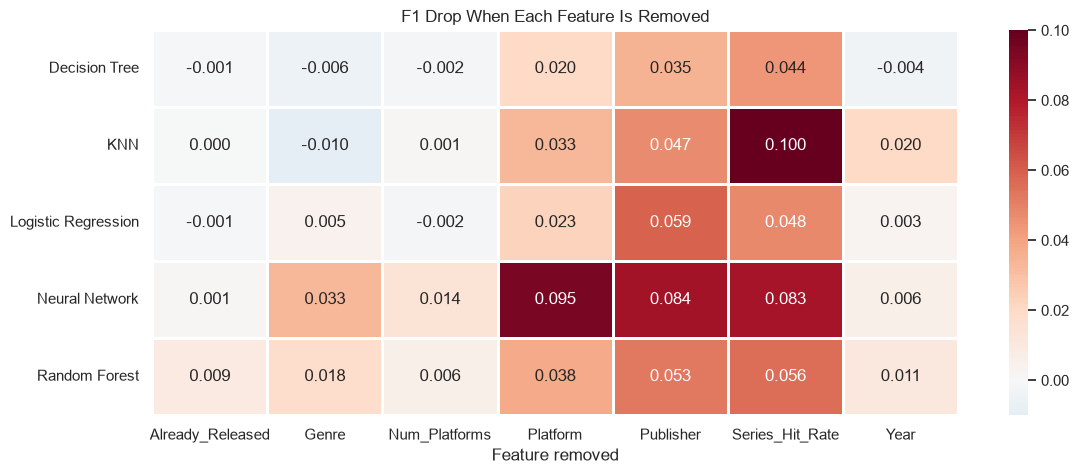

In [7]:
plt.figure(figsize=(13, 5))
sns.heatmap(drops, annot=True, fmt=".3f", cmap="RdBu_r", center=0, linewidths=1, linecolor="white")
plt.title("F1 Drop When Each Feature Is Removed")
plt.xlabel("Feature removed")
plt.ylabel("")
plt.savefig("charts/ablation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

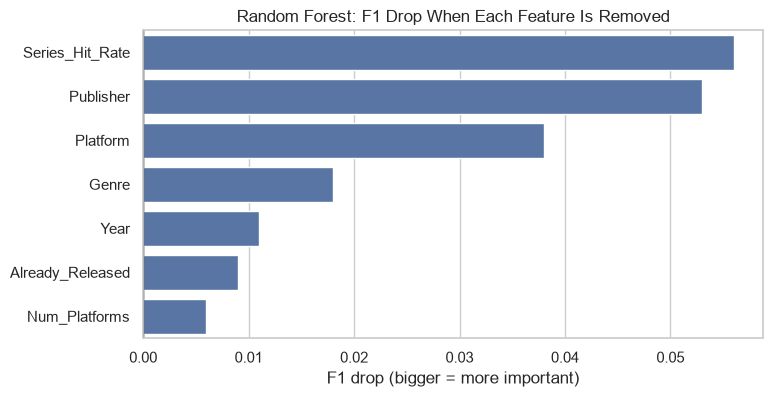

In [8]:
rf_drops = drops.loc["Random Forest"].sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=rf_drops.values, y=rf_drops.index)
plt.axvline(0, color="black", linewidth=1)
plt.title("Random Forest: F1 Drop When Each Feature Is Removed")
plt.xlabel("F1 drop (bigger = more important)")
plt.ylabel("")
plt.savefig("charts/ablation_random_forest.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
ablation.round(4).to_csv("results/ablation_scores.csv", index=False)
print("Saved! ✅")

Saved! ✅
